### Building a multi-table join with the Query Designer

SSMS can generate a join query visually. Steps:

1. Open a **New Query** window and select the `pubs` database.
2. Right-click an empty area of the query window and choose **Design Query in Editor...** (shortcut: `Ctrl+Shift+Q`).
3. In the **Add Table** dialog, add `titles`, `titleauthor`, `authors` and `publishers`, then click **Close**.
4. Check the join lines between the tables. The designer draws them automatically from the foreign keys.
5. Tick the checkbox next to each column you want in the result.
6. Review the generated SQL in the bottom pane, then click **OK** to paste it into the editor.
7. Press **F5** to run it.

The designer writes full table names instead of aliases, so the query works the same as an aliased one but is harder to read.





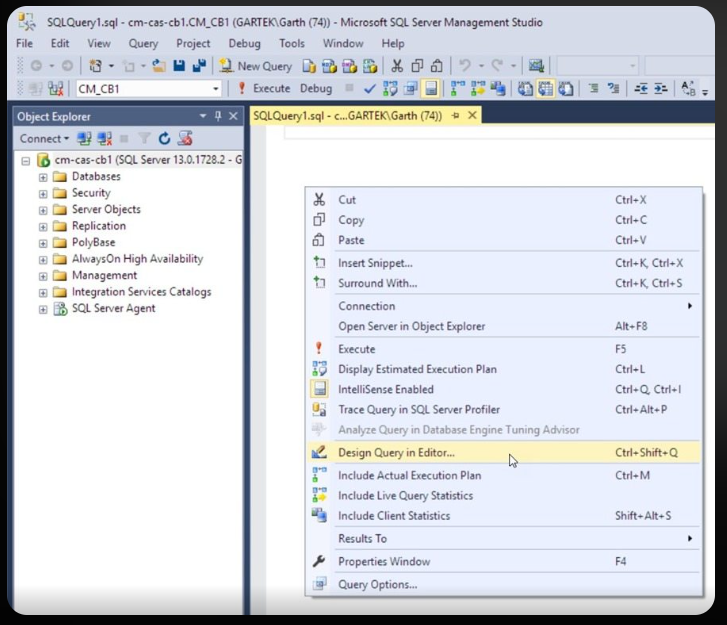

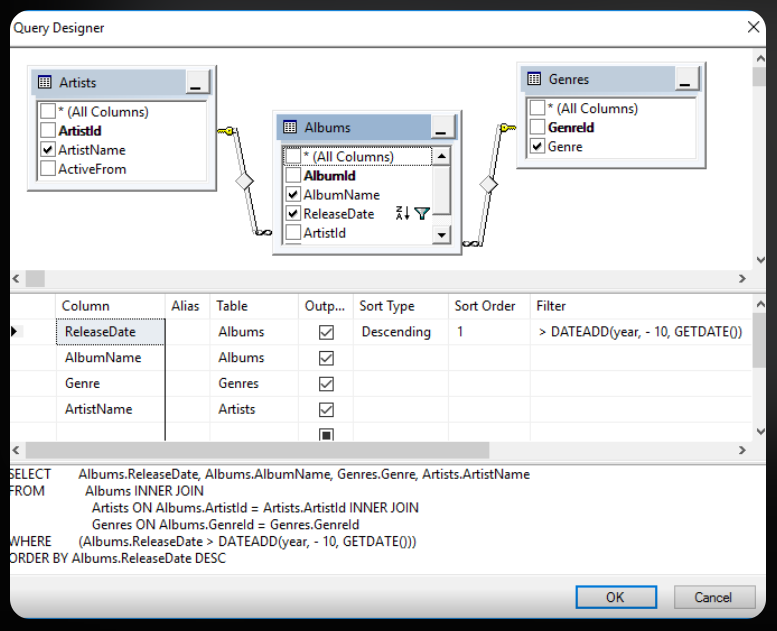



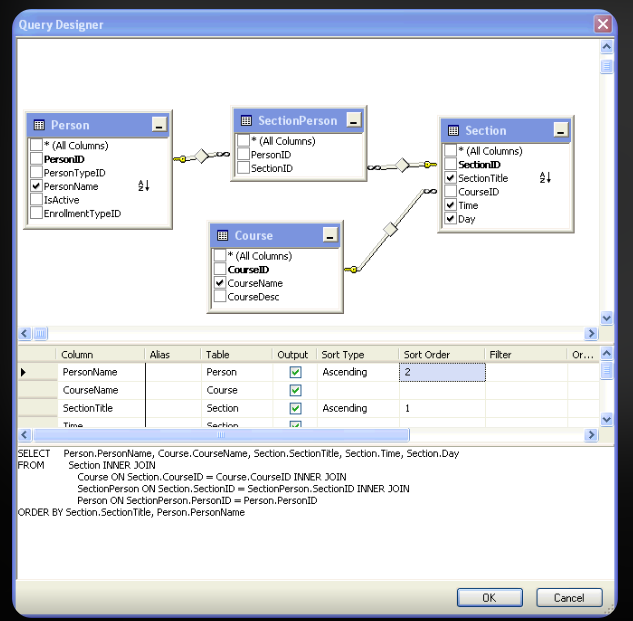




## Query Designer: every option explained

**Open it:** right-click an empty area of the query window → **Design Query in Editor...** (`Ctrl+Shift+Q`).

The designer has three panes that stay in sync. Change one and the other two update.

| Pane | What it is | What you do there |
|---|---|---|
| **Diagram pane** (top) | the tables as boxes, with join lines | add or remove tables, tick column checkboxes, edit joins |
| **Criteria pane** (middle grid) | one row per column | alias, sorting, grouping, filters |
| **SQL pane** (bottom) | the generated T-SQL | read the result, or type SQL and watch the other panes update |

You can show or hide each pane from the toolbar or the **Query Designer** menu. Click **OK** to paste the SQL into the query window, then press **F5** to run it.

### The Criteria grid, column by column

| Grid column | What it controls | SQL it generates |
|---|---|---|
| **Column** | the column name, or an **expression** you type yourself | the item in `SELECT` |
| **Alias** | a new name for the output column | `AS alias` |
| **Table** | which table the column belongs to | the `table.` prefix |
| **Output** | tick = show in the result; untick = hidden | in or out of `SELECT` |
| **Sort Type** | `Ascending` / `Descending` / blank | `ORDER BY ... ASC / DESC` |
| **Sort Order** | a number: priority when sorting by several columns (1 = first) | the order of items in `ORDER BY` |
| **Group By** | appears after you click **Add Group By**; chooses the grouping or aggregate for this column | `GROUP BY`, aggregate functions, or `WHERE` |
| **Criteria** | the first filter condition, for example `> 15` | `WHERE` (or `HAVING` on an aggregate) |
| **Or...** (several columns) | alternative filter conditions | `OR` |

Besides the grid, three more places hold options: the **join line** (join type), the **diagram pane right-click menu** (add tables, add group by), and the **Properties** window (DISTINCT, TOP, WITH ROLLUP/CUBE).

### 1. Output and Alias

* **Output** decides whether a column appears in the result. Untick it when you only need the column for a filter or a sort.
* **Alias** renames the output column. It is the same as `AS` in SQL. Use it for readable headings and for calculated columns.

**Example:** show `title_id`, `title` renamed to `BookTitle`, and `price` renamed to `Price`.

| Column | Table | Alias | Output |
|---|---|---|---|
| title_id | titles | | ✓ |
| title | titles | BookTitle | ✓ |
| price | titles | Price | ✓ |

In [ ]:
SELECT titles.title_id, titles.title AS BookTitle, titles.price AS Price
FROM   titles

```
title_id  BookTitle                                             Price
--------  ----------------------------------------------------  -----
BU1032    The Busy Executive's Database Guide                   19.99
BU1111    Cooking with Computers: Surreptitious Balance Sheets  11.95
BU2075    You Can Combat Computer Stress!                        2.99
BU7832    Straight Talk About Computers                         19.99
MC2222    Silicon Valley Gastronomic Treats                     19.99
(18 rows in total)
```

### 2. Sort Type and Sort Order

* **Sort Type:** `Ascending` or `Descending` for that column. Leave it blank for no sorting.
* **Sort Order:** when several columns are sorted, this number says which one counts first. `1` is the main sort, `2` breaks ties in the main sort, and so on.

Set the Sort Type first. The designer then fills in the Sort Order numbers in the order you chose.

**Example:** sort by `type` ascending (priority 1), then by `price` descending (priority 2).

| Column | Sort Type | Sort Order |
|---|---|---|
| type | Ascending | 1 |
| title | | |
| price | Descending | 2 |

To change the priority, edit the number in Sort Order. The SQL pane follows.

In [ ]:
SELECT titles.type, titles.title, titles.price
FROM   titles
ORDER BY titles.type, titles.price DESC

```
type          title                                                 price
------------  ----------------------------------------------------  -----
business      The Busy Executive's Database Guide                   19.99
business      Straight Talk About Computers                         19.99
business      Cooking with Computers: Surreptitious Balance Sheets  11.95
business      You Can Combat Computer Stress!                        2.99
mod_cook      Silicon Valley Gastronomic Treats                     19.99
mod_cook      The Gourmet Microwave                                  2.99
popular_comp  But Is It User Friendly?                              22.95
popular_comp  Secrets of Silicon Valley                             20.00
...
```
Within each `type`, prices run from highest to lowest. Rows with a `NULL` price appear at the end of each type group when sorting descending.

### 3. Criteria and Or...

Type a condition in the **Criteria** cell of a column, for example:

| What you type | Meaning |
|---|---|
| `'business'` or `= 'business'` | equals |
| `<> 'business'` | not equal |
| `> 15`, `>= 15`, `< 15` | comparisons |
| `LIKE 'S%'` | pattern match |
| `IN ('CA', 'NY')` | one of a list |
| `BETWEEN 10 AND 20` | range |
| `IS NULL` / `IS NOT NULL` | missing or present |

How the grid combines conditions:

* conditions in the **same row** (Criteria row, or the same Or... row) are joined with **AND**
* conditions in **different columns of the Or... group** (Criteria, Or..., Or...) are joined with **OR**

**Example:** books that are (`business` **and** price above 15) **or** `psychology`.

| Column | Criteria | Or... |
|---|---|---|
| type | `'business'` | `'psychology'` |
| price | `> 15` | |

The designer adds the `N` prefix to text and wraps each condition in parentheses.

In [ ]:
SELECT titles.title_id, titles.type, titles.price
FROM   titles
WHERE  (titles.type = N'business') AND (titles.price > 15)
    OR (titles.type = N'psychology')

```
title_id  type        price
--------  ----------  -----
BU1032    business    19.99
BU7832    business    19.99
PS1372    psychology  21.59
PS2091    psychology  10.95
PS2106    psychology   7.00
PS3333    psychology  19.99
PS7777    psychology   7.99
(7 rows)
```
`AND` binds tighter than `OR`, so the first two rows come from the business condition and the rest from the psychology condition.

### 4. Group By and aggregate functions

To group, click **Add Group By** (the Σ toolbar button, the **Query Designer** menu, or right-click in the diagram pane). A new **Group By** column appears in the grid, with `Group By` pre-filled on every row.

Open the drop-down in the **Group By** cell of a column. The choices are:

| Choice | SQL result | Use it when |
|---|---|---|
| **Group By** | column goes into `GROUP BY` | the column defines the groups |
| **Sum** | `SUM(column)` | total |
| **Avg** | `AVG(column)` | average |
| **Min** / **Max** | `MIN(column)` / `MAX(column)` | smallest / largest |
| **Count** | `COUNT(column)` | count non-`NULL` values |
| **Count_Big** | `COUNT_BIG(column)` | same, for very large tables (returns `bigint`) |
| **StDev** / **StDevP** | standard deviation (sample / population) | statistics |
| **Var** / **VarP** | variance (sample / population) | statistics |
| **Expression** | your own typed expression, such as `SUM(a * b)` | calculated aggregates (see example 7) |
| **Where** | the column is used only as a `WHERE` filter | filter without grouping (see example 6) |

**Example:** average price and number of titles **per publisher**.

| Column | Table | Alias | Group By |
|---|---|---|---|
| pub_name | publishers | | Group By |
| price | titles | AvgPrice | Avg |
| title_id | titles | CountOfTitles | Count |

The designer also added the join lines `publishers → titles`, so this uses the same `INNER JOIN` from the join session.

In [ ]:
SELECT publishers.pub_name, AVG(titles.price) AS AvgPrice, COUNT(titles.title_id) AS CountOfTitles
FROM   publishers
INNER JOIN titles ON publishers.pub_id = titles.pub_id
GROUP BY publishers.pub_name

```
pub_name              AvgPrice  CountOfTitles
--------------------  --------  -------------
Algodata Infosystems  18.976    6
Binnet & Hardley      15.41     7
New Moon Books         9.784    5
(3 rows)
```
Only three publishers appear because `INNER JOIN` drops publishers with no titles (example 9 changes that).

### 5. Criteria on an aggregate becomes HAVING

Where you type the condition decides the SQL clause:

| Condition typed on a column whose Group By cell is... | Generated clause |
|---|---|
| `Group By` | `WHERE` (filters rows before grouping) |
| `Where` | `WHERE` |
| `Sum`, `Avg`, `Count`, ... | `HAVING` (filters groups after aggregation) |

**Example:** keep only publishers whose average price is above 14.

| Column | Alias | Group By | Criteria |
|---|---|---|---|
| pub_name | | Group By | |
| price | AvgPrice | Avg | `> 14` |

In [ ]:
SELECT publishers.pub_name, AVG(titles.price) AS AvgPrice
FROM   publishers
INNER JOIN titles ON publishers.pub_id = titles.pub_id
GROUP BY publishers.pub_name
HAVING (AVG(titles.price) > 14)

```
pub_name              AvgPrice
--------------------  --------
Algodata Infosystems  18.976
Binnet & Hardley      15.41
(2 rows)
```
New Moon Books (average 9.784) is filtered out after grouping.

### 6. Group By = `Where`: filter without showing the column

Sometimes you want to filter on a column that is **not** in the result and **not** a grouping column. Set its Group By cell to **Where**, put the condition in Criteria, and untick **Output**.

**Example:** titles per publisher, but ignore `UNDECIDED` books.

| Column | Alias | Output | Group By | Criteria |
|---|---|---|---|---|
| pub_name | | ✓ | Group By | |
| title_id | CountOfTitles | ✓ | Count | |
| type | | | Where | `<> 'UNDECIDED'` |

In [ ]:
SELECT publishers.pub_name, COUNT(titles.title_id) AS CountOfTitles
FROM   publishers
INNER JOIN titles ON publishers.pub_id = titles.pub_id
WHERE  (titles.type <> N'UNDECIDED')
GROUP BY publishers.pub_name

```
pub_name              CountOfTitles
--------------------  -------------
Algodata Infosystems  6
Binnet & Hardley      6
New Moon Books        5
(3 rows)
```
Binnet & Hardley dropped from 7 titles (example 4) to 6, because its `UNDECIDED` title is excluded **before** counting.

### 7. Expression: calculated columns and aggregates

Type your own expression in the **Column** cell (instead of picking a column). For an expression that contains an aggregate, set Group By to **Expression**.

**Example:** total sales value per publisher: `SUM(sales.qty * titles.price)`, sorted from largest to smallest. This adds a fourth table, `sales`.

| Column | Alias | Group By | Sort Type |
|---|---|---|---|
| publishers.pub_name | | Group By | |
| `SUM(sales.qty * titles.price)` | TotalSales | Expression | Descending |

In [ ]:
SELECT publishers.pub_name, SUM(sales.qty * titles.price) AS TotalSales
FROM   publishers
INNER JOIN titles ON publishers.pub_id = titles.pub_id
INNER JOIN sales  ON titles.title_id   = sales.title_id
GROUP BY publishers.pub_name
ORDER BY TotalSales DESC

```
pub_name              TotalSales
--------------------  ----------
Algodata Infosystems  2586.95
Binnet & Hardley      2128.10
New Moon Books        1961.85
(3 rows)
```



### 8. Query-level options in the Properties window

Right-click an empty area of the **diagram pane** → **Properties**. These apply to the whole query:

| Property | Choices | SQL result |
|---|---|---|
| **Distinct Values** | Yes / No | `SELECT DISTINCT` |
| **Top Specification** | Yes / No | `TOP n` |
| ↳ **Expression** | a number | how many rows (or percent) |
| ↳ **Percent** | Yes / No | `TOP n PERCENT` |
| ↳ **With Ties** | Yes / No | `WITH TIES` (needs a Sort Type, otherwise there is no order to tie on) |
| **Group By Extension** | None / With Cube / With Rollup | `GROUP BY ... WITH CUBE` / `WITH ROLLUP` |

#### 8a. Top Specification with ties
**Example:** top 3 titles by total quantity sold. Set Top Specification = Yes, Expression = 3, With Ties = Yes, and Sort Type = Descending on the total.

In [ ]:
SELECT TOP (3) WITH TIES titles.title_id, SUM(sales.qty) AS TotalQty
FROM   titles
INNER JOIN sales ON titles.title_id = sales.title_id
GROUP BY titles.title_id
ORDER BY TotalQty DESC

```
title_id  TotalQty
--------  --------
PS2091    108
PC8888     50
MC3021     40
TC3218     40
(4 rows)
```
`TOP (3)` returned 4 rows because the third and fourth place both sold 40.

#### 8b. Distinct Values
**Example:** the list of book types. Tick only `type` in Output and set **Distinct Values = Yes**.

In [ ]:
SELECT DISTINCT titles.type
FROM   titles

```
type
------------
UNDECIDED
business
mod_cook
popular_comp
psychology
trad_cook
(6 rows)
```

#### 8c. Group By Extension: With Rollup
**Example:** titles per publisher and type, with subtotals. Group by `pub_name` and `type`, Count on `title_id`, then set **Group By Extension = With Rollup**.

In [ ]:
SELECT publishers.pub_name, titles.type, COUNT(titles.title_id) AS CountOfTitles
FROM   publishers
INNER JOIN titles ON publishers.pub_id = titles.pub_id
GROUP BY publishers.pub_name, titles.type WITH ROLLUP

```
pub_name              type          CountOfTitles
--------------------  ------------  -------------
NULL                  NULL          18      <- grand total
Algodata Infosystems  NULL           6      <- subtotal for the publisher
Algodata Infosystems  business       3
Algodata Infosystems  popular_comp   3
Binnet & Hardley      NULL           7
Binnet & Hardley      UNDECIDED      1
Binnet & Hardley      mod_cook       2
Binnet & Hardley      psychology     1
Binnet & Hardley      trad_cook      3
New Moon Books        NULL           5
New Moon Books        business       1
New Moon Books        psychology     4
(12 rows)
```
The `<-` notes are added for explanation. The designer does not print them, and SQL Server does not guarantee this row order unless you add an `ORDER BY`. `NULL` marks the rolled-up column, as in the extended grouping section.

### 9. Join lines: changing the join type

Right-click a **join line** in the diagram pane:

| Menu item | Join produced |
|---|---|
| *(default)* | `INNER JOIN` |
| **Select All Rows from publishers** | `LEFT OUTER JOIN` (all publishers, matches from titles) |
| **Select All Rows from titles** | `RIGHT OUTER JOIN` (all titles, matches from publishers) |
| both items ticked | `FULL OUTER JOIN` |
| **Remove** | deletes the join (never leave two tables without a join, or you get a cross join) |
| **Properties** | shows the two tables and the comparison operator (`=` by default; `<>`, `<`, `>` and so on are possible) |

You can also **drag** a column from one table onto a column of another to create a new join line.

**Example:** count titles for **every** publisher, including those with none. Right-click the line → **Select All Rows from publishers**.

In [ ]:
SELECT publishers.pub_name, COUNT(titles.title_id) AS CountOfTitles
FROM   publishers
LEFT OUTER JOIN titles ON publishers.pub_id = titles.pub_id
GROUP BY publishers.pub_name
ORDER BY CountOfTitles DESC

```
pub_name               CountOfTitles
---------------------  -------------
Binnet & Hardley       7
Algodata Infosystems   6
New Moon Books         5
Five Lakes Publishing  0
GGG&G                  0
Lucerne Publishing     0
Ramona Publishers      0
Scootney Books         0
(8 rows)
```
With `INNER JOIN` (example 4) only 3 publishers appeared. The `LEFT OUTER JOIN` keeps all 8, and `COUNT(titles.title_id)` gives 0 for publishers without titles, because it skips the `NULL`s that the missing matches produce.

### 10. Other diagram-pane tools

| Action | How | Result |
|---|---|---|
| **Add Table** | right-click the diagram pane → **Add Table...** | a new table box |
| **Remove a table** | right-click the table box → **Remove** | table disappears from the query |
| **Add Derived Table** | right-click → **Add Derived Table...** | a subquery in `FROM`, with an alias |
| **Check/untick a column** | checkbox in the table box | adds or removes it from `SELECT` (it appears in the grid too) |
| **`*` (All Columns)** | tick the `* (All Columns)` item | `table.*` |
| **Edit SQL directly** | type in the SQL pane | the diagram and grid update to match |

Tip: if you type SQL the designer cannot display (a `CASE` expression, a window function), it shows a message and keeps your text. Use the designer for the skeleton, then finish by hand in the editor.

### Cheat sheet: designer option → SQL

| In the designer | In SQL |
|---|---|
| tick **Output** | column in `SELECT` |
| **Alias** | `AS alias` |
| **Sort Type** + **Sort Order** | `ORDER BY` (order = priority) |
| **Criteria** (Group By / Where) | `WHERE` |
| **Criteria** (on Sum, Avg, Count...) | `HAVING` |
| **Or...** columns | `OR` |
| **Add Group By** → *Group By* | `GROUP BY` |
| **Add Group By** → *Sum / Avg / Min / Max / Count* | aggregate function |
| **Add Group By** → *Expression* | typed calculation or aggregate |
| **Add Group By** → *Where* | filter-only column |
| Properties → **Distinct Values** | `DISTINCT` |
| Properties → **Top Specification** (+ With Ties) | `TOP n [WITH TIES]` |
| Properties → **Group By Extension** | `WITH ROLLUP` / `WITH CUBE` |
| join line → *Select All Rows from...* | `LEFT` / `RIGHT` / `FULL OUTER JOIN` |